# 4. Band structure and density of states

After the self-consistent cycle the Hamiltonian is known, and its eigenvalues can be obtained at any
k-point without further iterations. This tutorial plots the band structure of silicon along symmetry lines
and builds a density of states.

**You will learn** to define a path in the Brillouin zone, read off band gaps, write a SIESTA `.bands` file,
and compute a density of states from eigenvalues on a dense grid.

Run time: under a minute.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

import jax_siesta as js
from jax_siesta.app import write_bands
from jax_siesta.scf import build_monkhorst_pack_mesh

PSEUDOS = Path("../../examples/pseudos").resolve()
WORK = Path("work/04")
WORK.mkdir(parents=True, exist_ok=True)
plt.rcParams["figure.dpi"] = 90

a = 5.47
cell = a * np.array([[0.0, 0.5, 0.5], [0.5, 0.0, 0.5], [0.5, 0.5, 0.0]])
silicon = js.make_structure(cell, ["Si", "Si"], [[0, 0, 0], [0.25, 0.25, 0.25]], fractional=True)

calc = js.Calculation.from_structure(
    silicon, PSEUDOS, basis="DZP", k_grid=(6, 6, 6), xc_functional="PBE",
    mesh_cutoff_ry=150.0, use_symmetry=True, label="si",
)
results = calc.run()
print("converged:", results.converged, " Fermi level:", round(results.fermi_level_ev, 3), "eV")

converged: True  Fermi level: -3.734 eV


## A path through the Brillouin zone

k-points are given in units of the reciprocal lattice vectors. For the fcc lattice with the primitive vectors
used here the special points are

| point | coordinates |
|---|---|
| Γ | (0, 0, 0) |
| X | (1/2, 0, 1/2) |
| L | (1/2, 1/2, 1/2) |
| W | (1/2, 1/4, 3/4) |
| K | (3/8, 3/8, 3/4) |

energies array (channels, k-points, bands): (1, 201, 26)


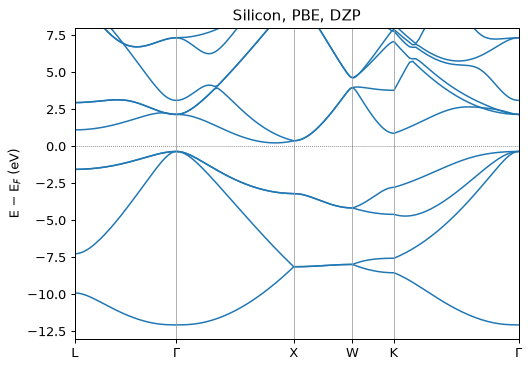

In [2]:
path = [
    ("L", (0.5, 0.5, 0.5)),
    ("Γ", (0.0, 0.0, 0.0)),
    ("X", (0.5, 0.0, 0.5)),
    ("W", (0.5, 0.25, 0.75)),
    ("K", (0.375, 0.375, 0.75)),
    ("Γ", (0.0, 0.0, 0.0)),
]
bands = results.band_structure(path, points_per_segment=40)
print("energies array (channels, k-points, bands):", bands.energies_ev.shape)

fig, ax = plt.subplots(figsize=(6, 4.2))
bands.plot(ax=ax)
ax.set_ylim(-13, 8)
ax.set_title("Silicon, PBE, DZP")
fig.tight_layout()

The four lowest bands hold the eight valence electrons; zero is the Fermi level, which for an insulator lies
somewhere in the gap.

## Band gaps

In [3]:
n_occ = bands.n_occupied
e = bands.energies_ev[0]
vbm_k = np.argmax(e[:, n_occ - 1])
cbm_k = np.argmin(e[:, n_occ])
print(f"occupied bands: {n_occ}")
print(f"valence-band maximum at k = {np.round(bands.kpoints_frac[vbm_k], 3)}")
print(f"conduction-band minimum at k = {np.round(bands.kpoints_frac[cbm_k], 3)}  (about 85 % of the way from Γ to X)")
print(f"indirect gap: {bands.band_gap_ev:.3f} eV")
gamma = results.eigenvalues_ev([[0.0, 0.0, 0.0]])[0, 0]
print(f"direct gap at Γ: {gamma[n_occ] - gamma[n_occ - 1]:.3f} eV")

occupied bands: 4
valence-band maximum at k = [0. 0. 0.]
conduction-band minimum at k = [0.425 0.    0.425]  (about 85 % of the way from Γ to X)
indirect gap: 0.578 eV


direct gap at Γ: 2.503 eV


The experimental indirect gap of silicon is 1.17 eV. A gap of roughly half that value is the well-known
behaviour of semilocal functionals such as PBE, not a numerical problem. The position of the conduction-band
minimum along Γ-X is reproduced.

## Writing a SIESTA `.bands` file

The same data in SIESTA's format, for tools such as `gnubands` or `sisl`. (With the `jsiesta` command, a
`%block BandLines` in the input file does this automatically.)

In [4]:
write_bands(WORK / "si.bands", bands)
print("\n".join((WORK / "si.bands").read_text().splitlines()[:5]))

      -3.73437709651823
       0.00000000000000       2.29780372649645
     -15.79814227909935     101.94825669593502
          26           1         201
  0.000000    -13.6429    -10.9951     -5.2914     -5.2914     -2.6225     -0.7810     -0.7810      5.4388      6.5420      6.5420


## Density of states

The density of states counts eigenvalues per unit energy, averaged over the Brillouin zone. We take the
eigenvalues on a 12 x 12 x 12 grid, much denser than the one used for self-consistency, and replace each one
by a Gaussian.

electrons from integrating the DOS up to the Fermi level: 8.0 (expected 8)


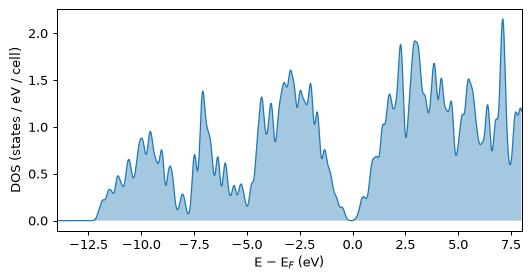

In [5]:
dense = build_monkhorst_pack_mesh((12, 12, 12))
eig = results.eigenvalues_ev(dense.kpoints_frac)[0]  # (n_k, n_bands)
weights = np.asarray(dense.weights)

energy = np.linspace(-14.0, 8.0, 800) + results.fermi_level_ev
sigma = 0.10  # eV
gauss = np.exp(-0.5 * ((energy[:, None, None] - eig[None]) / sigma) ** 2) / (sigma * np.sqrt(2.0 * np.pi))
dos = 2.0 * np.einsum("ekb,k->e", gauss, weights)  # factor 2 for spin

fig, ax = plt.subplots(figsize=(6, 3.2))
ax.fill_between(energy - results.fermi_level_ev, dos, alpha=0.4)
ax.plot(energy - results.fermi_level_ev, dos, lw=1.0)
ax.set_xlabel("E − E$_F$ (eV)")
ax.set_ylabel("DOS (states / eV / cell)")
ax.set_xlim(-14, 8)
fig.tight_layout()

below = energy <= results.fermi_level_ev
print("electrons from integrating the DOS up to the Fermi level:",
      round(float(np.sum(dos[below]) * (energy[1] - energy[0])), 3), "(expected 8)")

Integrating the density of states up to the Fermi level recovers the eight valence electrons, a useful
sanity check of grids and broadening.

## Exercises

1. **Graphene.** Build a graphene sheet (a = 2.46 Å, 15 Å of vacuum, pseudopotential `C.psml`), run it with a
   12 x 12 x 1 k-grid, and plot the bands along Γ-M-K-Γ with M = (1/2, 0, 0) and K = (1/3, 1/3, 0). Where
   do the valence and conduction bands touch? *(Solution in the Solutions notebook.)*
2. How does the silicon gap change with the basis (`SZ`, `DZ`, `DZP`, `TZP`)? Which bands move most: valence
   or conduction? Why would you expect that?
3. Reduce the SCF k-grid to 2 x 2 x 2 and plot the bands again. The bands barely change even though the total
   energy is not converged. Why?
4. Compute the density of states with `sigma = 0.02` on the same grid. What do the spikes tell you about the
   grid density needed for a given broadening?